# Data Exploration and Preprocessing 

## Data understanding 
working on the bike_types.csv file 

### Load the data 

In [2]:
import pandas as pd
import numpy as np

# Load the data
bike_types = pd.read_csv("../data/raw/bike_types.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

### Infos of the data 

characteristics of bikes,

In [3]:
bike_types.head()

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
0,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
bike_types.info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                121 non-null    int64  
 1   vehicle_image     91 non-null     str    
 2   name              91 non-null     str    
 3   description       51 non-null     str    
 4   form_factor       91 non-null     str    
 5   rider_capacity    91 non-null     float64
 6   propulsion_type   91 non-null     str    
 7   max_range         15 non-null     float64
 8   battery_capacity  22 non-null     float64
dtypes: float64(3), int64(1), str(5)
memory usage: 8.6 KB


valeurs nulles 

In [5]:
bike_types.isna().sum()
bike_types.isna().sum().sum()       # total count
bike_types.isna().mean() * 100

id                   0.000000
vehicle_image       24.793388
name                24.793388
description         57.851240
form_factor         24.793388
rider_capacity      24.793388
propulsion_type     24.793388
max_range           87.603306
battery_capacity    81.818182
dtype: float64

Plage de valeurs :

In [6]:
bike_types.describe()

,id,rider_capacity,max_range,battery_capacity
count,121.000000,91.000000,15.0,22.000000
mean,134.454545,1.230769,60000.0,547.727273
std,77.738450,0.423659,0.0,61.638873
min,0.000000,1.000000,60000.0,500.000000
25%,72.000000,1.000000,60000.0,500.000000
50%,149.000000,1.000000,60000.0,500.000000
75%,201.000000,1.000000,60000.0,600.000000
max,254.000000,2.000000,60000.0,690.000000


max_range est vide à 88 % et vaut toujours 60 000 quand il est renseigné. battery_capacity est vide à 82 % et varie" de 500 à 690. Ces deux colonnes n'apportent presque rien, et c'est pareil pour vehicle_image et description.

Visualiser la distribution :

array([[<Axes: title={'center': 'id'}>,
        <Axes: title={'center': 'rider_capacity'}>],
       [<Axes: title={'center': 'max_range'}>,
        <Axes: title={'center': 'battery_capacity'}>]], dtype=object)

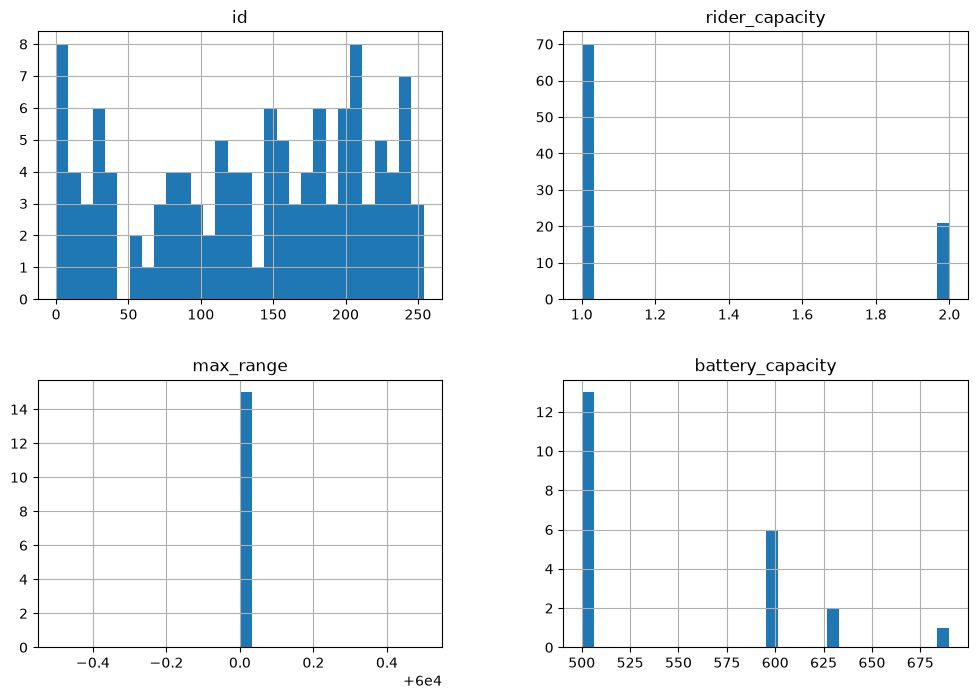

In [8]:
bike_types.hist(figsize=(12, 8), bins=30)


In [9]:
# 1. Lignes vides : à garder, mais marquées "unknown" plutôt que supprimées
#    (1 050 vélos y renvoient, les supprimer ferait perdre leurs trajets)
empty = bike_types.drop(columns="id").isna().all(axis=1)
print(f"{empty.sum()} types vides")

bt = bike_types.copy()
bt[["form_factor", "propulsion_type"]] = bt[["form_factor", "propulsion_type"]].fillna("unknown")

# 2. Garder seulement les colonnes utiles + une variable simple
bt = bt[["id", "name", "form_factor", "propulsion_type", "rider_capacity"]]
bt["is_electric"] = bt["propulsion_type"].map(
    {"electric_assist": 1, "human": 0, "unknown": np.nan})

# 3. Croiser les deux variables principales
pd.crosstab(bt["form_factor"], bt["propulsion_type"])


30 types vides


propulsion_type,electric_assist,human,unknown
form_factor,,,
bicycle,15,56,0
cargo_bicycle,12,7,0
other,0,1,0
unknown,0,0,30


## Data understanding 
working on the bike.csv file 

In [10]:
bikes = pd.read_csv("../data/raw/bikes.csv", na_values=["NA", "NULL", "None", "Not Applicable"])

In [11]:
bikes.head()

,id,bike_type_id,computer_id
0,400481,196,83300002927
1,374044,204,7551171765
2,373778,204,7551140444
3,34749,14,0
4,88359,143,7551052355


In [12]:
bikes.info()

<class 'pandas.DataFrame'>
RangeIndex: 88436 entries, 0 to 88435
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            88436 non-null  int64
 1   bike_type_id  88436 non-null  int64
 2   computer_id   88436 non-null  int64
dtypes: int64(3)
memory usage: 2.0 MB


In [13]:
bikes.isna().sum()
bikes.isna().sum().sum()       # total count
bikes.isna().mean() * 100

id              0.0
bike_type_id    0.0
computer_id     0.0
dtype: float64

In [14]:
bikes.describe()

,id,bike_type_id,computer_id
count,88436.000000,88436.000000,8.843600e+04
mean,287347.736182,130.639739,6.533541e+09
std,262380.844954,68.631175,8.500256e+09
min,2204.000000,0.000000,0.000000e+00
25%,45033.500000,71.000000,7.551012e+09
50%,224069.500000,150.000000,7.551068e+09
75%,485216.500000,196.000000,7.551120e+09
max,998499.000000,254.000000,7.551011e+11


In [15]:
# Doublons
print("id en double :", bikes["id"].duplicated().sum())

id en double : 0


In [16]:
# computer_id = 0 : sans doute "pas d'ordinateur", ou une valeur manquante codée par 0
print("computer_id == 0 :", (bikes["computer_id"] == 0).sum())

computer_id == 0 : 13136


on a 13136 valeurs nulles de computer_id, donc "pas d'ordinateur" pour le bike => il faut remplacer les valeurs nulles pas NaN 

In [17]:
# Doublons de computer_id, en ignorant les 0
non_zero = bikes[bikes["computer_id"] != 0]
print("computer_id en double :", non_zero["computer_id"].duplicated().sum())

computer_id en double : 3023


3023 doublons => des boitiers utilises d'un velo a l'autre 

### Conclusion :
Ici pas de valeurs manquantes, la table est un pont entre les trajets et les caracteristques de velos, il faut faire une fusion avec la table bike_types afin de savoir l'information du trajet est fait avec quel type de velo 